# Ambiguous folds: a koi and a red sun on a crane

The flat sheet reads as one scene: the Tokyo skyline at dusk under sakura and a pine branch. Folding the crane cuts two pieces out of that scene, and each resolves into something else: a red sun on one wing and a koi on the other. Dalí's double images work this way: context decides what a shape is.

**What folding does to a wing.** Each crane wing is an upright triangle made of two shards of the sheet. On the flat sheet, those shards lie along two different edges, and they touch only at a corner tip. Folding does three things to them at once:

- **cuts** them out of their surroundings
- **turns** each by a different angle
- **joins** them along an edge that was never shared on the sheet

**The two methods.** Each is a set of views of the sheet, each view with its own prompt. They're sampled together as in [MultiDiffusion](https://arxiv.org/abs/2302.08113) (Bar-Tal et al., ICML 2023): at every denoising step, every view's prediction is mapped back onto the sheet and averaged per pixel.

| Method | Views and prompts |
| --- | --- |
| `average` | the flat sheet with the Tokyo prompt, and each folded wing with its own prompt. A plain average |
| `arcimboldo` | the Tokyo prompt controls only the large shapes. The folded wings, and nine overlapping windows that each ask for a close-up of the scene, control the fine detail |

**What we found.** With DeepFloyd's M model, arcimboldo won: it drew a cicada with the same branch strokes and blossoms as the rest of the scene, and the average left it faint or pasted on. With the XL model, the plain average won on the koi. Its flat sheet is a real skyline, with Tokyo Tower, and in arcimboldo the windows turned the whole sheet into branches and blossoms.

**How a run goes:**

1. Stage 1 (64 pixels) decides the layout, so it's run alone first to check that the wings get a sun and a koi. That depends mostly on the seed.
2. Stage 2 (256 pixels) refines it, for both methods.
3. Print the one you like, as is or upscaled to 1024 pixels.

The other methods tried (`context`, `silhouette`, `fold-in`) are still in `ambiguous.py`, and `ambiguous.METHODS` lists them.

## Setup

In [1]:
import importlib, os, subprocess, sys

FOLDER = "fold-map"
if not os.path.exists("ambiguous.py"):
    if not os.path.exists("folded-illusions"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/rath-hy/folded-illusions.git"], check=True)
    os.chdir(os.path.join("folded-illusions", FOLDER))
if "google.colab" in sys.modules:
    # On Colab, rerunning this cell gets the latest code and reloads anything already imported.
    subprocess.run(["git", "pull", "-q"], check=True)
    for name in ["fold_map", "decal", "illusion", "factorized", "ambiguous"]:
        if name in sys.modules:
            importlib.reload(sys.modules[name])
sys.path.insert(0, os.getcwd())

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from fold_map import FoldedModel
from decal import test_picture
from illusion import FoldViews, plot_result, print_page, square_picture
import ambiguous

## The crane's wings, in place and folded

Each row shows the flat sheet, then for each wing its two shards in place on the flat sheet with their surroundings, then the folded view. The letter is a stand-in picture. In place, the shards are just part of the A's background. Folded, they become the crane's body.

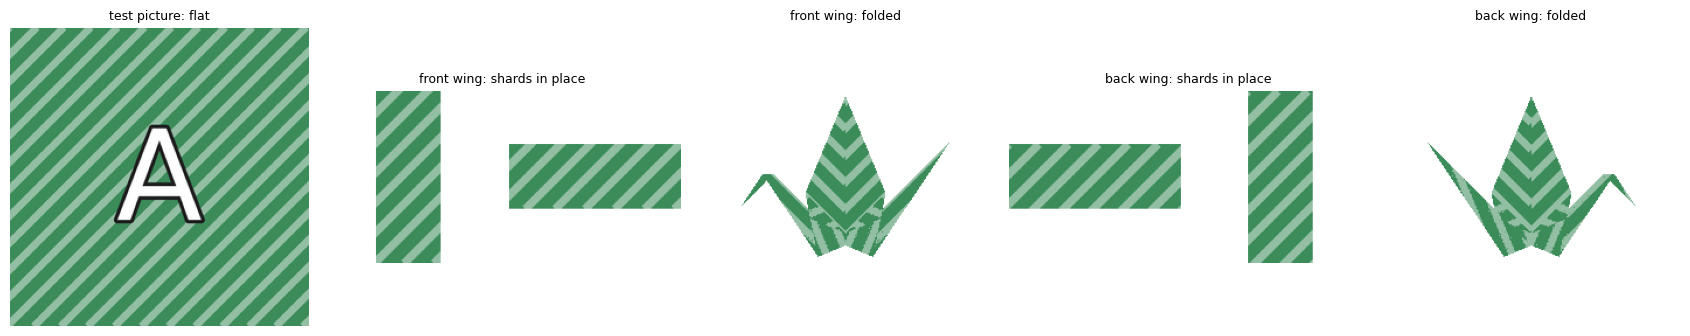

front wing shards: [2022, 2022] sheet pixels each
back wing shards: [2022, 2022] sheet pixels each


In [2]:
model = FoldedModel("004_traditional_Crane_cp.fold", "004_traditional_Crane_state.fold")
views64, views256 = FoldViews(model, 64), FoldViews(model, 256)

test_sheet = square_picture(test_picture("A", (60, 140, 90), (1000, 1000)), 256)
ambiguous.plot_reveal(views256, {"test picture": test_sheet})
plt.show()
for side in ("front", "back"):
    print(side, "wing shards:", [int(m.sum()) for m in ambiguous.wing_shards(views256, side)], "sheet pixels each")

## What each method shows the model

Every tile below is one view: what the model is shown for it at every denoising step, with its prompt key and weight. Gray is the plain backdrop. Faded pixels have less say in the blend. Views marked low or high control only those frequencies. Read this to see what each method asks for before spending GPU time.

- `CONTEXT_WEIGHT` is the windows' total say at every pixel. Each window fades out across its overlap with its neighbors, so together they add up to the same weight everywhere and leave no seams. 1.0 gives them as much say as the folded views.
- `EDGE_FADE` is how far every view but the flat one fades out where its paper meets the gray backdrop, as a fraction of the sheet's side: 1 pixel at stage 1, 4 at stage 2. The model draws an edge wherever paper meets backdrop. Without the fade, the folded crane's outline left straight lines across the flat sheet, and the windows drew a frame along the sheet's border, which shows as a line down the middle of each folded wing: the two wing shards join along the sheet's border.

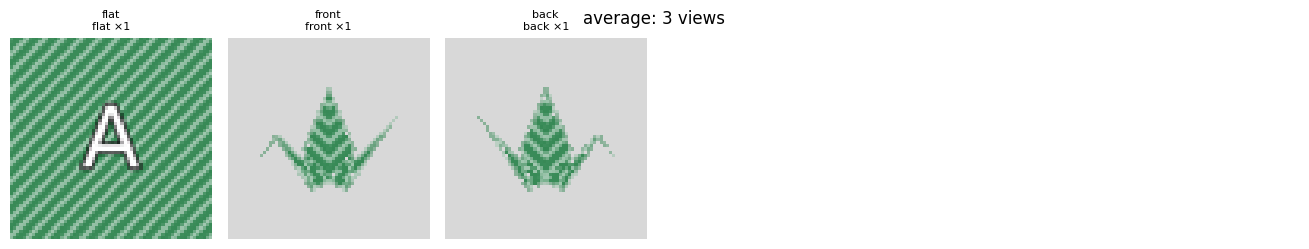

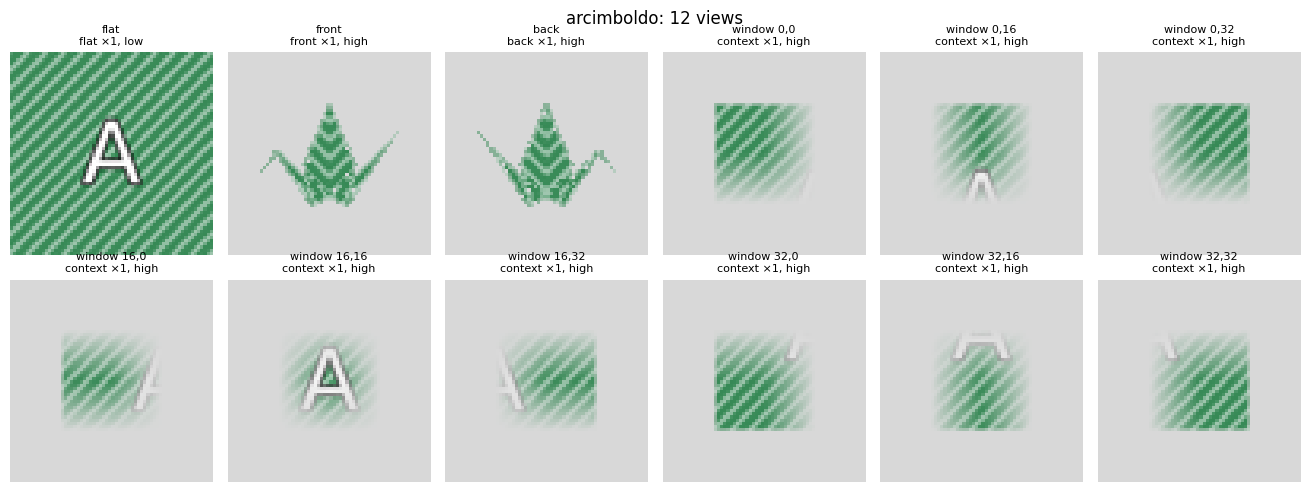

In [3]:
METHODS = ("average", "arcimboldo")
CONTEXT_WEIGHT = 1.0
EDGE_FADE = ambiguous.EDGE_FADE

def views_for(method, fv):
    return ambiguous.method_views(method, fv, context_weight=CONTEXT_WEIGHT, edge_fade=EDGE_FADE)

test64 = square_picture(test_picture("A", (60, 140, 90), (1000, 1000)), 64)
for method in METHODS:
    fig = ambiguous.plot_views(views_for(method, views64), test64)
    fig.suptitle(f"{method}: {len(views_for(method, views64))} views", y=1.02)
    plt.show()

## Generate (needs a GPU)

Setup matches the other notebooks.

1. Use a **GPU runtime** (Runtime → Change runtime type). A T4 works for `MODEL_SIZE = "M"`. For `"XL"`, use an L4 or A100.
2. On Hugging Face, accept the licenses for [DeepFloyd/IF-I-M-v1.0](https://huggingface.co/DeepFloyd/IF-I-M-v1.0) and [DeepFloyd/IF-II-M-v1.0](https://huggingface.co/DeepFloyd/IF-II-M-v1.0), and for `XL` also [DeepFloyd/IF-I-XL-v1.0](https://huggingface.co/DeepFloyd/IF-I-XL-v1.0) and [DeepFloyd/IF-II-L-v1.0](https://huggingface.co/DeepFloyd/IF-II-L-v1.0), and have an [access token](https://huggingface.co/settings/tokens) ready.

In [4]:
# protobuf 7.36 or later: current transformers ships a tokenizer file older protobuf can't read.
!pip install -q -U diffusers transformers accelerate sentencepiece "protobuf>=7.36"
import sys
if "google.protobuf" in sys.modules:
    print("protobuf was already loaded before this upgrade: choose Runtime → Restart session, then run from the top.")
from huggingface_hub import notebook_login
notebook_login()

### Prompts

- **`FLAT_PROMPT`, `FRONT_PROMPT`, `BACK_PROMPT`:** the flat sheet, the front wing and the back wing.
- **`CONTEXT_PROMPT`:** what a small piece of the flat scene should look like up close, for arcimboldo's windows. It's built from the flat scene's own elements, so a piece that obeys it belongs in the scene.
- **`VIEW_TITLES`:** labels for the plots.

**What makes a wing subject work.** A wing is only about 16 × 32 pixels at stage 1, where the layout is decided. A subject has to read at that size, as a bold silhouette against plain sky:

- **Worked:** a crisp disc for the sun, whose edge is fine detail. A smooth sunset didn't: it's a gradient, and the flat sky is already orange. A cicada or koi silhouette worked too.
- **Didn't:** a yen sign. Its two bars are a pixel thick at stage 1, so even XL drew only a Y. Also, DeepFloyd's T5 text encoder has no `¥` token: it becomes unknown, so a symbol has to be described in words.
- **Bright scarlet** keeps the sun's disc lighter than the dark branches around it. Crimson came out close to them.

In [14]:
STYLE = "an oil painting of "
FLAT_PROMPT = STYLE + (
    "the Tokyo skyline at dusk with a dark textured pine branch along the left edge, "
    "framed by soft blooming sakura trees, under a glowing orange and white sky"
)
FRONT_PROMPT = STYLE + "a large bright scarlet red sun, a vivid saturated perfect crisp-edged disc like the one on the Japanese flag, center in the picture against a pale white sky streaked with thin horizontal bands of cloud"
BACK_PROMPT = STYLE + "a black silhouette koi fish, slightly angled, against a plain glowing orange sky"
CONTEXT_PROMPT = STYLE + "a close-up of dark sakura branches and Tokyo rooftops silhouetted against a glowing orange and white sky, with paper lanterns"

PROMPTS = dict(flat=FLAT_PROMPT, front=FRONT_PROMPT, back=BACK_PROMPT, context=CONTEXT_PROMPT)
VIEW_TITLES = ("flat: Tokyo", "red sun wing", "koi wing")

### Encode the prompts

Rerun this cell whenever you change the prompts.

In [15]:
import gc, torch
from transformers import T5EncoderModel
from diffusers import IFPipeline, IFSuperResolutionPipeline

# The safety checker and watermarker aren't used by our sampler, and the safety checker
# doesn't load with current versions of transformers, so skip them.
skip = dict(safety_checker=None, feature_extractor=None, watermarker=None)

# Every model size uses the same T5 text encoder, so this always loads it from the M repo.
text_encoder = T5EncoderModel.from_pretrained("DeepFloyd/IF-I-M-v1.0", subfolder="text_encoder", variant="fp16",
                                              torch_dtype=torch.float16, device_map="cuda")
encoder = IFPipeline.from_pretrained("DeepFloyd/IF-I-M-v1.0", text_encoder=text_encoder, unet=None, **skip)
embeds = ambiguous.encode_prompts(encoder, PROMPTS)

del encoder, text_encoder
gc.collect(); torch.cuda.empty_cache()
print("encoded:", ", ".join(embeds))

encoded: flat, front, back, context


### Load the image models

`MODEL_SIZE` picks DeepFloyd's model sizes:

- **`"M"`:** stage 1 is `IF-I-M` (0.4B parameters) and stage 2 is `IF-II-M`. Fast, and fits a T4.
- **`"XL"`:** stage 1 is `IF-I-XL` (4.3B) and stage 2 is `IF-II-L` (1.2B). Much better at following the prompt and drawing clean shapes, but several times slower, and about 11 GB of weights: use an L4 or A100. On a T4, lower `BATCH_SIZE` if it runs out of memory.

A seed gives a different picture at each size, so screen and finish with the same size. This cell loads the models once per session, and again only when `MODEL_SIZE` changes. If memory is tight, run it after encoding the prompts, since T5 alone takes about 9.5 GB.

In [16]:
MODEL_SIZE = "XL"             # "M" or "XL"
MODELS = {"M": ("DeepFloyd/IF-I-M-v1.0", "DeepFloyd/IF-II-M-v1.0"),
          "XL": ("DeepFloyd/IF-I-XL-v1.0", "DeepFloyd/IF-II-L-v1.0")}

if globals().get("loaded_size") != MODEL_SIZE:
    for name in ("stage_1", "stage_2"):
        globals().pop(name, None)
    gc.collect(); torch.cuda.empty_cache()
    repo_1, repo_2 = MODELS[MODEL_SIZE]
    stage_1 = IFPipeline.from_pretrained(repo_1, text_encoder=None, variant="fp16",
                                         torch_dtype=torch.float16, **skip).to("cuda")
    stage_2 = IFSuperResolutionPipeline.from_pretrained(repo_2, text_encoder=None, variant="fp16",
                                                        torch_dtype=torch.float16, **skip).to("cuda")
    loaded_size = MODEL_SIZE
print(f"models: {MODEL_SIZE}, {torch.cuda.memory_allocated() / 2**30:.1f} GB in use")

models: XL, 10.4 GB in use


### 1. Stage 1: the layout

Stage 1 decides the layout: whether a wing gets its subject at all is settled here, and it depends mostly on the seed. Run it alone on a few seeds, which is cheap, and keep the ones whose wings already show a sun and a koi. Each seed shows its flat sheet and its two wings as folded, at 64 pixels.

- `SIGMA_FRAC` is arcimboldo's frequency split at stage 1 and at stage 2, as a fraction of the sheet's side (0: no split, a plain weighted average).
- `NOISE_LEVEL` is how much noise stage 2 adds to the upscaled stage-1 sheet it's guided by. Lower keeps stage 2 closer to stage 1.
- `BATCH_SIZE` is views per model call at each stage. Lower it if the GPU runs out of memory.

arcimboldo, seed 0, stage 1: 98 s


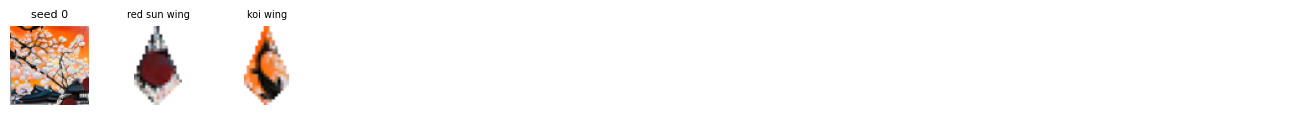

In [17]:
import time

SIGMA_FRAC = (1 / 8, 0.0)     # arcimboldo's split at stage 1 and stage 2
NOISE_LEVEL = 100
GUIDANCE = (7.0, 4.0)
STEPS = (50, 40)
BATCH_SIZE = (12, 4)
SCREEN_SEEDS = range(1)       # try range(12) to find a seed whose wings work

settings = dict(guidance=GUIDANCE, steps=STEPS, batch_size=BATCH_SIZE)
results = {}                  # label: (stage-1 sheet, final sheet)

def stage_one(method, seed):
    start = time.time()
    s1, _ = ambiguous.generate(stage_1, None, views_for(method, views64), None, embeds,
                               sigma_frac=SIGMA_FRAC, seed=seed, **settings)
    print(f"{method}, seed {seed}, stage 1: {time.time() - start:.0f} s")
    return s1

def stage_two(method, seed, s1, sigma_frac=None, noise_level=None):
    start = time.time()
    _, s2 = ambiguous.generate(None, stage_2, None, views_for(method, views256), embeds, stage1=s1, seed=seed,
                               sigma_frac=SIGMA_FRAC if sigma_frac is None else sigma_frac,
                               noise_level=NOISE_LEVEL if noise_level is None else noise_level, **settings)
    print(f"{method}, seed {seed}, stage 2: {time.time() - start:.0f} s")
    return s2

screen = {seed: stage_one("arcimboldo", seed) for seed in SCREEN_SEEDS}
ambiguous.plot_screen(views64, {f"seed {s}": s1 for s, s1 in screen.items()}, VIEW_TITLES)
plt.show()

### 2. Stage 2 for both methods

Stage 2 for each picked seed with arcimboldo, using its stage-1 sheet above, and with the plain average, both stages.

arcimboldo, seed 0, stage 2: 113 s
average, seed 0, stage 1: 26 s
average, seed 0, stage 2: 29 s


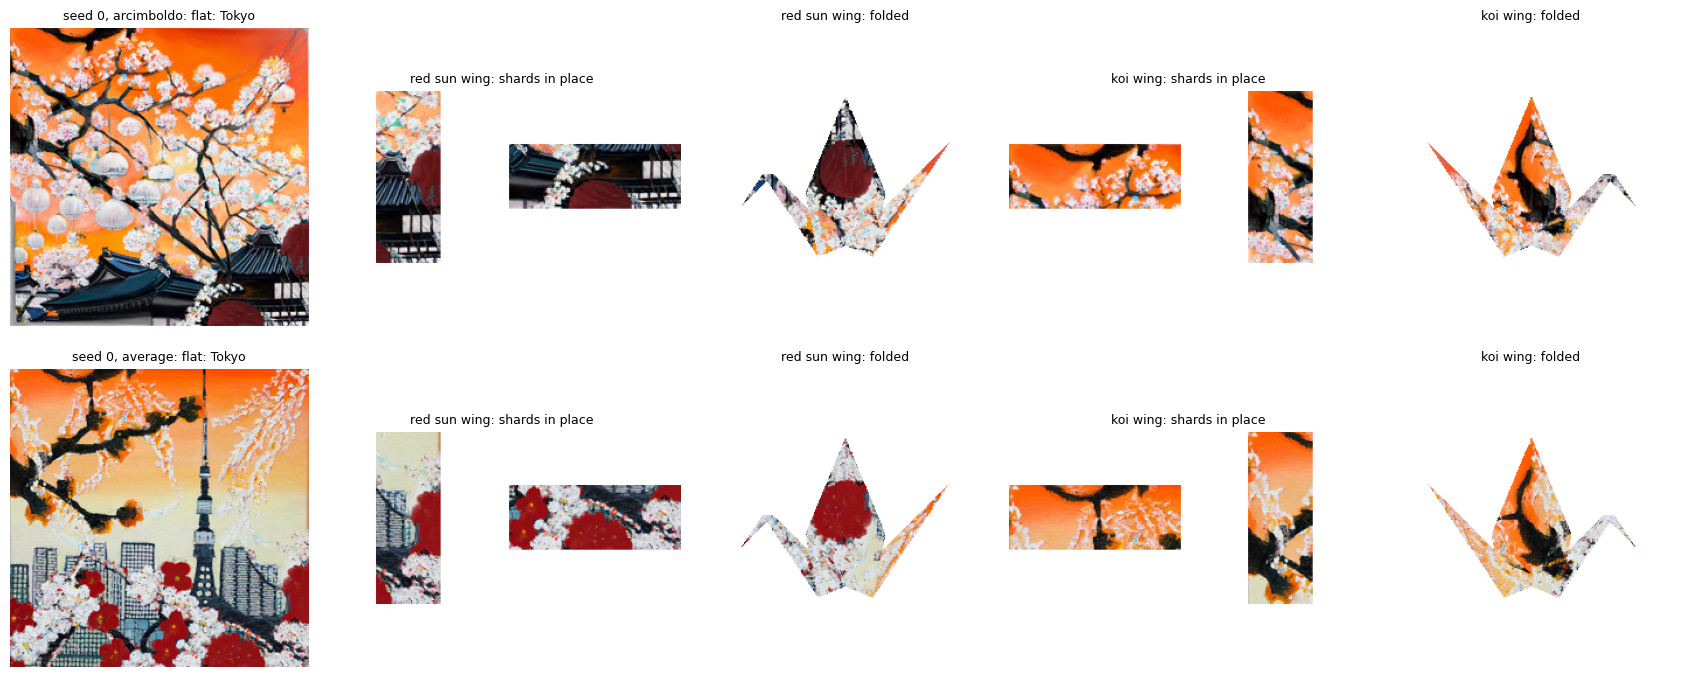

In [19]:
PICKS = (0,)                  # seeds from the screen worth finishing

batch = {f"seed {seed}, arcimboldo": (screen[seed], stage_two("arcimboldo", seed, screen[seed])) for seed in PICKS}
for seed in PICKS:
    s1 = stage_one("average", seed)
    batch[f"seed {seed}, average"] = (s1, stage_two("average", seed, s1))
results.update(batch)
ambiguous.plot_reveal(views256, {k: s2 for k, (_, s2) in batch.items()}, VIEW_TITLES)
plt.show()

### 3. Print

Set `BEST` to the result to print, from the labels above. This folds it virtually and saves an A4 PDF with the sheet at 200 mm, about the largest square a home printer can print on A4. Print at **actual size** (100%, not "fit to page"), cut along the gray line, and fold with the **printed side out**: corner A becomes the tail, C the head, and B and D the wing tips.

Download before disconnecting the runtime, because `results` lives only in its memory.

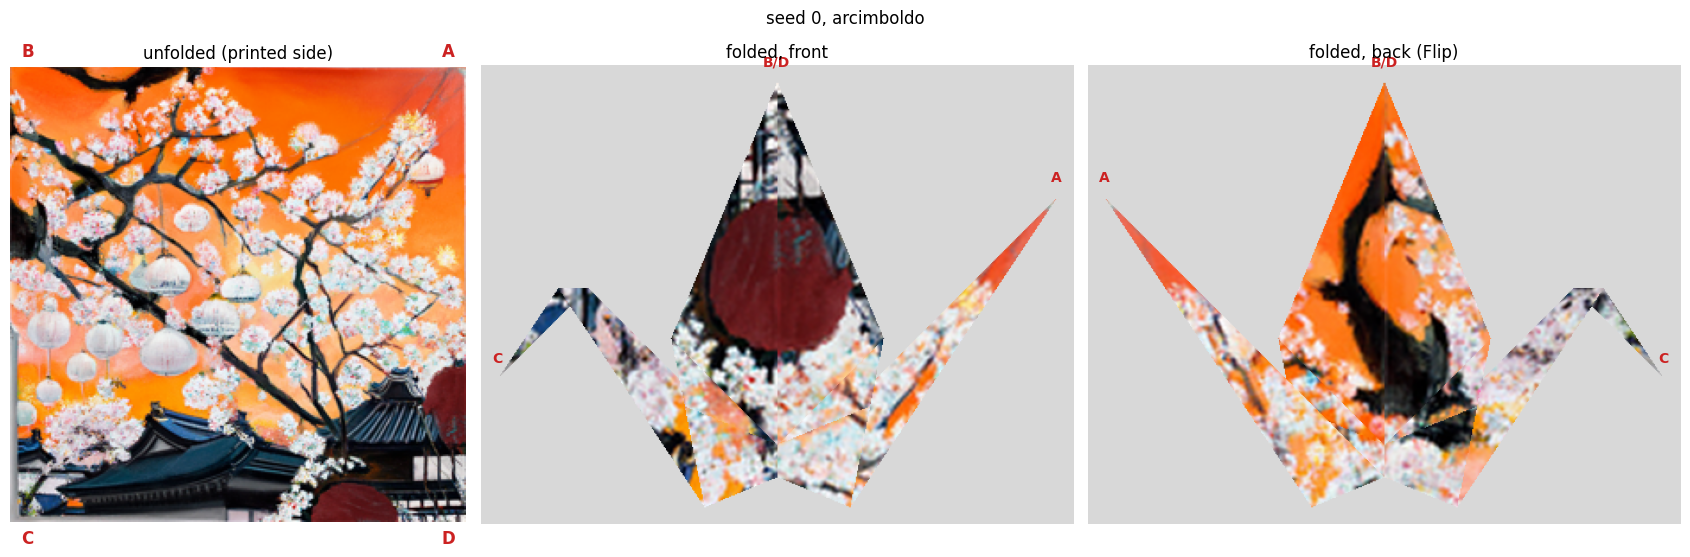

In [22]:
BEST = "seed 0, arcimboldo"
sheet = results[BEST][1]
print_page(sheet, "koi_crane_a4.pdf")
plot_result(views256, sheet, BEST)   # optional: the virtual fold, to check it's the right one
plt.show()

try:
    from google.colab import files
    files.download("koi_crane_a4.pdf")
except ImportError:
    pass

### 4. Upscale to 1024 pixels and print

The sheet is 256 pixels, which prints at about 1.3 mm per pixel. Stability's [x4 upscaler](https://huggingface.co/stabilityai/stable-diffusion-x4-upscaler), DeepFloyd's suggested third stage, takes it to 1024. It sees only the flat sheet, not the fold, so:

- **`UPSCALE_PROMPT`** is neutral. A prompt about Tokyo could paint rooftops into the wings.
- **`UPSCALE_NOISE`** is how much it may redraw. At 20 it mostly sharpens. Higher adds painterly texture, but may redraw the sun's edge or the koi's outline.

Check the wings in the comparison before printing. This frees the image models, so rerun the load cell to generate again.

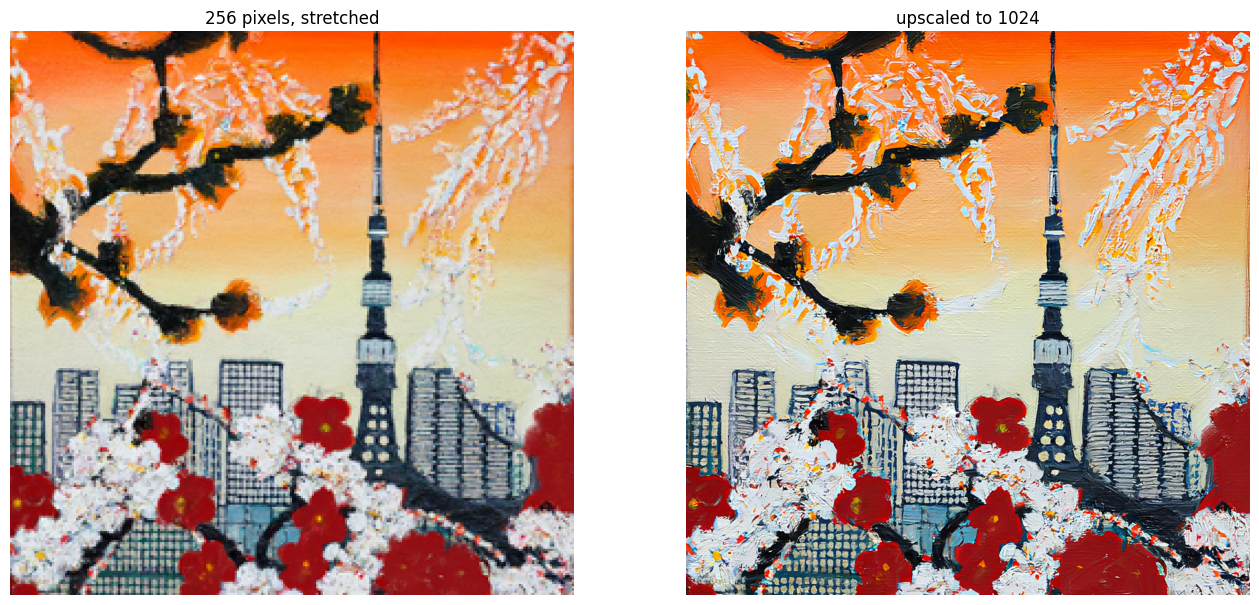

In [23]:
import gc, torch
from diffusers import StableDiffusionUpscalePipeline
from PIL import Image

BEST = "seed 0, average"
UPSCALE_PROMPT = "an oil painting, fine visible brush strokes, sharp detail"
UPSCALE_NOISE = 20        # how much the upscaler may redraw: lower stays closer to the 256-pixel sheet

# Free the IF models to make room. Rerun the load cell to bring them back.
for name in ("stage_1", "stage_2", "loaded_size"):
    globals().pop(name, None)
gc.collect(); torch.cuda.empty_cache()

if "upscaler" not in globals():
    upscaler = StableDiffusionUpscalePipeline.from_pretrained(
        "stabilityai/stable-diffusion-x4-upscaler", torch_dtype=torch.float16).to("cuda")
    upscaler.enable_attention_slicing()

low = Image.fromarray((np.clip(results[BEST][1], 0, 1) * 255).round().astype(np.uint8))
big = upscaler(prompt=UPSCALE_PROMPT, image=low, noise_level=UPSCALE_NOISE, num_inference_steps=50,
               generator=torch.Generator("cuda").manual_seed(0)).images[0]
sheet_hi = np.asarray(big, float) / 255
results[BEST + ", 1024"] = (results[BEST][0], sheet_hi)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(low.resize((1024, 1024), Image.NEAREST)); axes[0].set_title("256 pixels, stretched")
axes[1].imshow(big); axes[1].set_title("upscaled to 1024")
for ax in axes: ax.axis("off")
plt.show()

name = "koi_crane_a4_1024.pdf"
print_page(sheet_hi, name)
try:
    from google.colab import files
    files.download(name)
except ImportError:
    pass